# Tracer dispersion 1: diffusion between two walls

**37EFM Environmental Fluid Mechanics, TU/e**

A blob of tracer is released at mid-depth in a channel of depth $H = 10$ m, the channel of the turbulent Couette exercise. In this first notebook the flow is uniform and the diffusivity $D$ is a constant, so that everything can be checked against Chapter 6 of the notes: the variance of a Gaussian patch grows as $\sigma^2 = 2Dt$, and the time to diffuse across the depth is $H^2/D$.

The question to settle with numbers is **how long it takes for the blob to spread across the channel**, first with the molecular viscosity of water and then with a turbulent diffusivity of the size the Couette flow produces.

The solver, `efmtracer.eulerian`, integrates

$$\frac{\partial c}{\partial t} + u(z)\frac{\partial c}{\partial x} = \frac{\partial}{\partial x}\left(D_x\frac{\partial c}{\partial x}\right) + \frac{\partial}{\partial z}\left(D(z)\frac{\partial c}{\partial z}\right)$$

on a grid, periodic in $x$ and with no-flux walls at $z = -H$ and $z = 0$, in a frame moving with the depth-averaged velocity. Read `efmtracer/eulerian.py`: the along-$x$ step is done in Fourier space and the vertical step with implicit finite volumes.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from efmtracer import eulerian, lagrangian, profiles, theory
plt.rcParams['figure.dpi'] = 80

## The numbers first

For the Couette channel, $H = 10$ m. Compare the vertical diffusion time $H^2/D$ for the molecular viscosity of water and for the depth-averaged turbulent diffusivity of the Couette simulation.

In [2]:
H = 10.0
nu = 1.3e-6                                   # molecular viscosity of water [m^2/s]
couette = profiles.couette()                  # profiles of the GOTM Couette run (see notebook 2)
D_turb = couette.D_mean
for label, D in [('molecular', nu), ('turbulent (depth average of the Couette run)', D_turb)]:
    T = theory.mixing_time(H, D)
    print(f'{label:48s} D = {D:.2e} m^2/s   H^2/D = {T:.3g} s = {T / 86400:.3g} days')

molecular                                        D = 1.30e-06 m^2/s   H^2/D = 7.69e+07 s = 890 days
turbulent (depth average of the Couette run)     D = 3.10e-02 m^2/s   H^2/D = 3.22e+03 s = 0.0373 days


## A blob between two walls

Release a Gaussian blob at mid-depth, with $\sigma_{x,0} = 5$ m and $\sigma_{z,0} = 0.5$ m, in a uniform flow $u = 0.5$ m/s, with a constant diffusivity. The run is in the frame moving with the flow, so the blob stays in place in the plots. To keep the run short, take $D = 0.01$ m$^2$/s; the result for any other $D$ follows by scaling time with $H^2/D$.

In [3]:
D = 0.01
prof = profiles.constant(H, u=0.5, D=D)
grid = eulerian.Grid(L=400, nx=400, H=H, nz=100)
c0 = eulerian.gaussian_blob(grid, x0=200, z0=-H / 2, sigma_x=5.0, sigma_z=0.5)
solver = eulerian.Solver(grid, prof.u, prof.D)

T_mix = theory.mixing_time(H, D)
t_end = 1.0 * T_mix
times, snaps, hist = solver.run(c0, dt=5.0, t_end=t_end, save_every=t_end / 5)
print(f'H^2/D = {T_mix:.0f} s; run to {t_end:.0f} s in {len(hist["t"]) - 1} steps; mass {hist["mass"][0]:.4f} -> {hist["mass"][-1]:.4f}')

H^2/D = 10000 s; run to 10000 s in 2000 steps; mass 1.0000 -> 1.0000


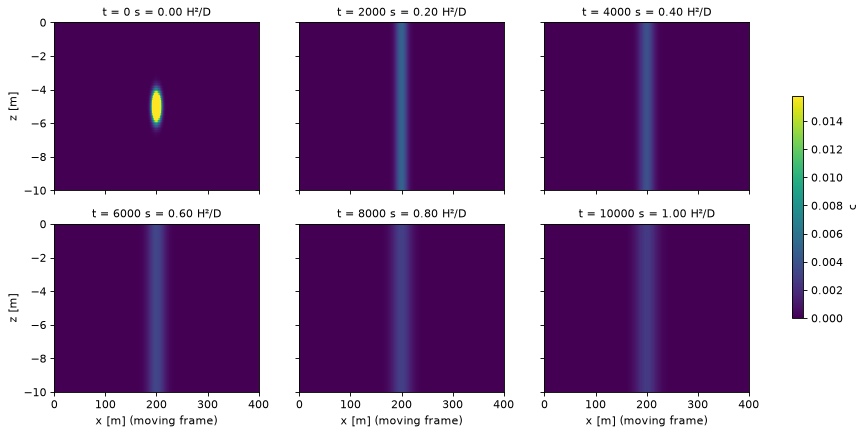

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(14, 6), sharex=True, sharey=True)
for ax, t, c in zip(axs.ravel(), times, snaps):
    pc = ax.pcolormesh(grid.x, grid.z, c, cmap='viridis', vmin=0, vmax=c0.max() / 4, shading='nearest')
    ax.set_title(f't = {t:.0f} s = {t / T_mix:.2f} H²/D', fontsize=10)
for ax in axs[1]: ax.set_xlabel('x [m] (moving frame)')
for ax in axs[:, 0]: ax.set_ylabel('z [m]')
fig.colorbar(pc, ax=axs, shrink=0.6, label='c');

## Variance against time

In $x$ nothing stops the spreading, so $\sigma_x^2 = \sigma_{x,0}^2 + 2Dt$ for ever. In $z$ the walls stop it: the variance saturates at the value of a uniform distribution, $H^2/12$.

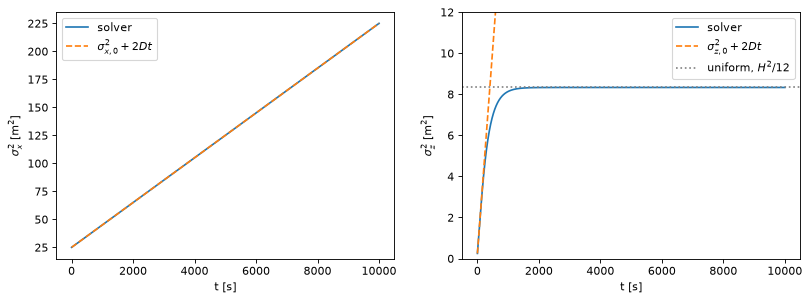

In [5]:
t = hist['t']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(t, hist['var_x'], label='solver'); ax1.plot(t, 25 + 2 * D * t, '--', label=r'$\sigma_{x,0}^2 + 2Dt$')
ax1.set_xlabel('t [s]'); ax1.set_ylabel(r'$\sigma_x^2$ [m$^2$]'); ax1.legend()
ax2.plot(t, hist['var_z'], label='solver'); ax2.plot(t, 0.25 + 2 * D * t, '--', label=r'$\sigma_{z,0}^2 + 2Dt$')
ax2.axhline(H ** 2 / 12, color='gray', ls=':', label='uniform, $H^2/12$')
ax2.set_xlabel('t [s]'); ax2.set_ylabel(r'$\sigma_z^2$ [m$^2$]'); ax2.set_ylim(0, 12); ax2.legend();

## The vertical profile and the time to uniformity

The depth-integrated... no, the $x$-integrated concentration is a function of $z$ and $t$ alone, and its exact solution between two walls is a cosine series whose $n$-th term decays as $\exp(-n^2\pi^2 Dt/H^2)$. The slowest term sets the time to become uniform: within 1 % after $t \approx 0.54\,H^2/D$.

Use this to answer the question: how long for the molecular case, and how long for the turbulent one?

molecular : uniform within 1 % after 4.13e+07 s = 1.15e+04 h = 478 days
turbulent : uniform within 1 % after 1.73e+03 s = 0.481 h = 0.02 days


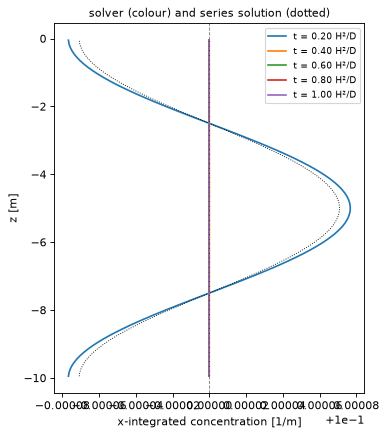

In [6]:
fig, ax = plt.subplots(figsize=(5, 6))
for t_snap, c in zip(times[1:], snaps[1:]):
    cz = c.sum(axis=1) * grid.dx                       # integrated over x
    ax.plot(cz, grid.z, label=f't = {t_snap / T_mix:.2f} H²/D')
    ax.plot(theory.wall_bounded_profile(grid.z, t_snap, -H / 2, D, H, sigma0=0.5), grid.z, 'k:', lw=0.8)
ax.axvline(1 / H, color='gray', ls='--', lw=0.8)
ax.set_xlabel('x-integrated concentration [1/m]'); ax.set_ylabel('z [m]'); ax.legend(fontsize=8)
ax.set_title('solver (colour) and series solution (dotted)', fontsize=10)

for label, Dval in [('molecular', nu), ('turbulent', D_turb)]:
    tu = theory.uniformity_time(H, Dval)
    print(f'{label:10s}: uniform within 1 % after {tu:.3g} s = {tu / 3600:.3g} h = {tu / 86400:.3g} days')

## Questions

1. The time to uniformity with the molecular viscosity is years; with the turbulent diffusivity it is about an hour. Where does the factor between them come from, and what does the Couette simulation say about it?
2. The run above used $D = 0.01$ m$^2$/s. Show, from the equation, that the solution for any other constant $D$ is the same function of $Dt/H^2$.
3. Change the initial position of the blob to near the wall. How does the approach to uniformity change?
4. Halve the time step and double the number of vertical cells. Does the solution change? Which of the two steps of the solver (along $x$, along $z$) has a truncation error?